In [514]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# Obtaining Prices for Analysis

In [515]:
# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

[*********************100%%**********************]  6 of 6 completed


In [516]:
# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

In [517]:
# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()
# Save for Model Validation
data.to_csv('stock_quotes_and_rates.csv')       # Saving

In [518]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470742,11.523580,27.337227,1.442398,60.505966,47.728802,0.700
2010-01-05,6.481926,11.486513,27.387941,1.436596,60.221508,47.642601,0.699
2010-01-06,6.378824,11.589477,27.680920,1.440403,60.805817,47.599602,0.694
2010-01-07,6.367033,11.704796,27.173834,1.431803,61.497757,47.562500,0.692
2010-01-08,6.409364,11.820113,26.261099,1.441109,62.328091,47.728401,0.691
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,3.931
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,3.931
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,3.925


### Calculating Credit Risk

In [519]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    T = len(credit)
    t = np.arange(T)#.reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [520]:
credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

The `data` object now represents the risk factors $(Z_j)_{j\in I}$ of our portfolio, so that we can define $\ell_{[t]}^\Delta(Z)$.

In [521]:
data

,AAPL,AIRBUS,ASML,EUR_USD,LVMH,EURO50,EURIBOR
Date,,,,,,,
2010-01-04,6.470742,11.523580,27.337227,1.442398,60.505966,47.728802,0.000019
2010-01-05,6.481926,11.486513,27.387941,1.436596,60.221508,47.642601,0.000019
2010-01-06,6.378824,11.589477,27.680920,1.440403,60.805817,47.599602,0.000019
2010-01-07,6.367033,11.704796,27.173834,1.431803,61.497757,47.562500,0.000019
2010-01-08,6.409364,11.820113,26.261099,1.441109,62.328091,47.728401,0.000019
...,...,...,...,...,...,...,...
2023-12-22,193.353287,137.034973,682.389404,1.100619,737.700012,109.199997,0.000106
2023-12-26,192.803986,137.034973,682.389404,1.102026,737.700012,109.199997,0.000106
2023-12-27,192.903839,137.015320,683.687134,1.104301,735.400024,109.440002,0.000105


In [522]:
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

<Axes: xlabel='Date'>

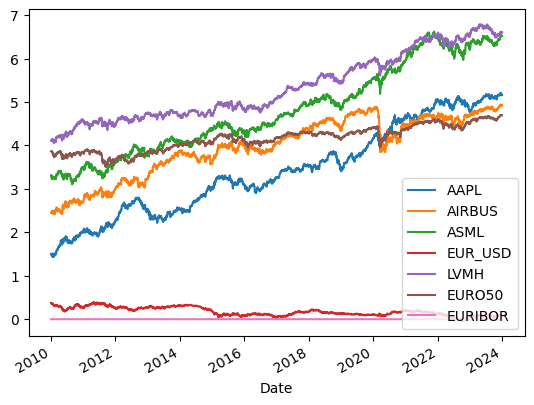

In [523]:
log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])

log_data.plot()

# Declaring Loss Operator

In [524]:
def loss_operator(Z, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = np.zeros(len(Z) - 1)
    loss_ind = Z[:-1].copy()
    T = len(Z) - 1
    t = np.arange(T)
    for Z_k, weight, name in zip(Z.values.T, weights, Z.columns):
        X_k = np.diff(Z_k)
        X_k = np.array([0] + X_k.tolist())
        X_k_shifted = X_k[1:] # from t = 2 to T
        X_k = X_k[:-1]  # from t = 1 to T - 1
        Z_k = Z_k[:-1]
        if name == 'AAPL':
            # Include EUR/USD exposure
            loss_sub = Value * weight * np.exp((Z_k - Z_k[0]) + (Z['EUR_USD'][:-1] - Z['EUR_USD'][0])) * X_k_shifted
        elif name == 'EURIBOR':
            # The time risk
            w = Value * np.exp(Z_k[0])
            loss_sub = -w * np.exp(-(T-t) * Z_k) * Z_k

            # Add credit risk
            loss_sub += Value * weight * np.exp(Z_k[0] - (T - t) * Z_k) * (T - t) * X_k
        else:
            loss_sub = Value * weight * np.exp(Z_k - Z_k[0]) * X_k_shifted
        loss += loss_sub
        loss_ind[name] = loss_sub * (1 / (weight)) if name != 'EUR_USD' else 0
    return -loss, -loss_ind

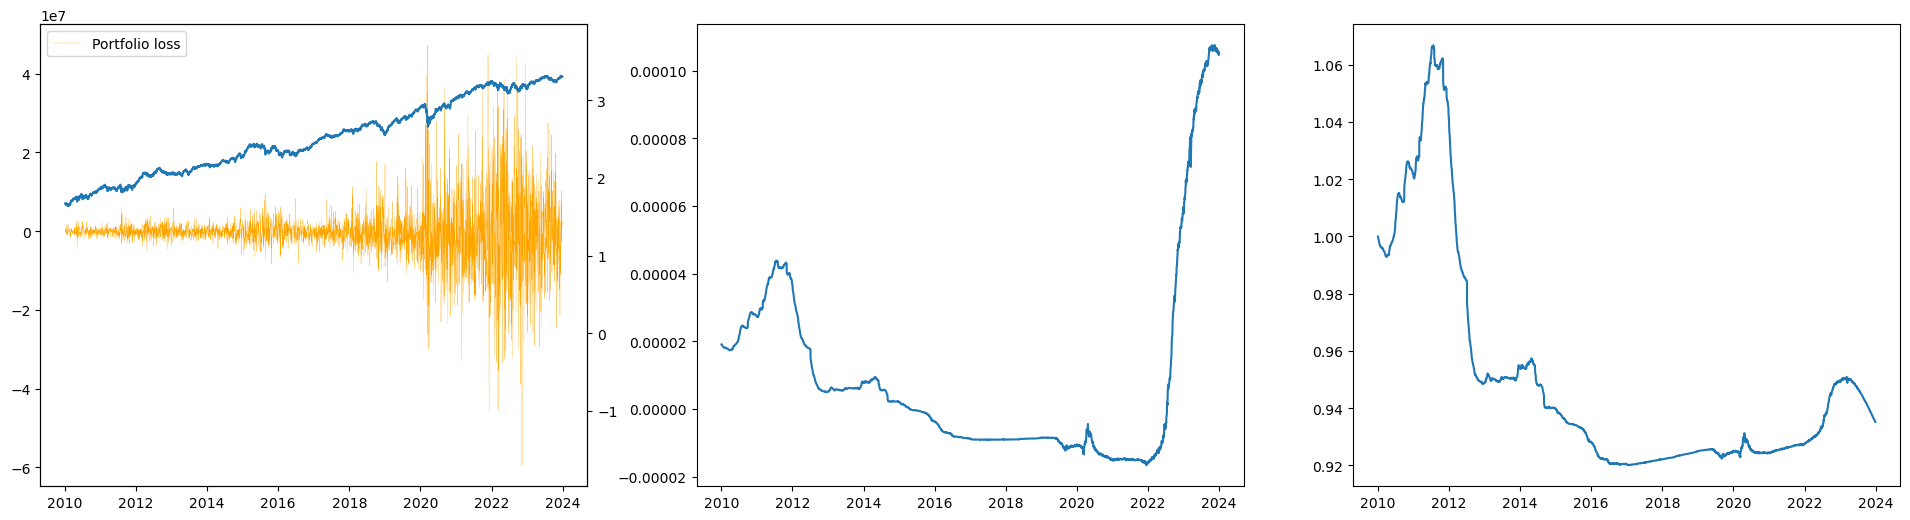

In [525]:
portfolio_loss, ind_loss = loss_operator(data, weights)
fig, axs = plt.subplots(1,3, figsize = (24, 6))
axs[0].plot(portfolio_loss, label = 'Portfolio loss', lw = 0.2, color='orange')
ax = axs[0].twinx()
PV = np.sum(weights * data, axis = 1)
ax.plot(PV)
ax.set_ylim(1.2 * max(-PV), 1.2 * max(PV))
axs[1].plot(data['EURIBOR'])
axs[2].plot(credit_val.loc[data.index])
axs[0].legend()
plt.show()

# Declaring methods to calculate VaR

### VaR CoVar

In [526]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.ppf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError()

In [527]:
window_size = 250 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

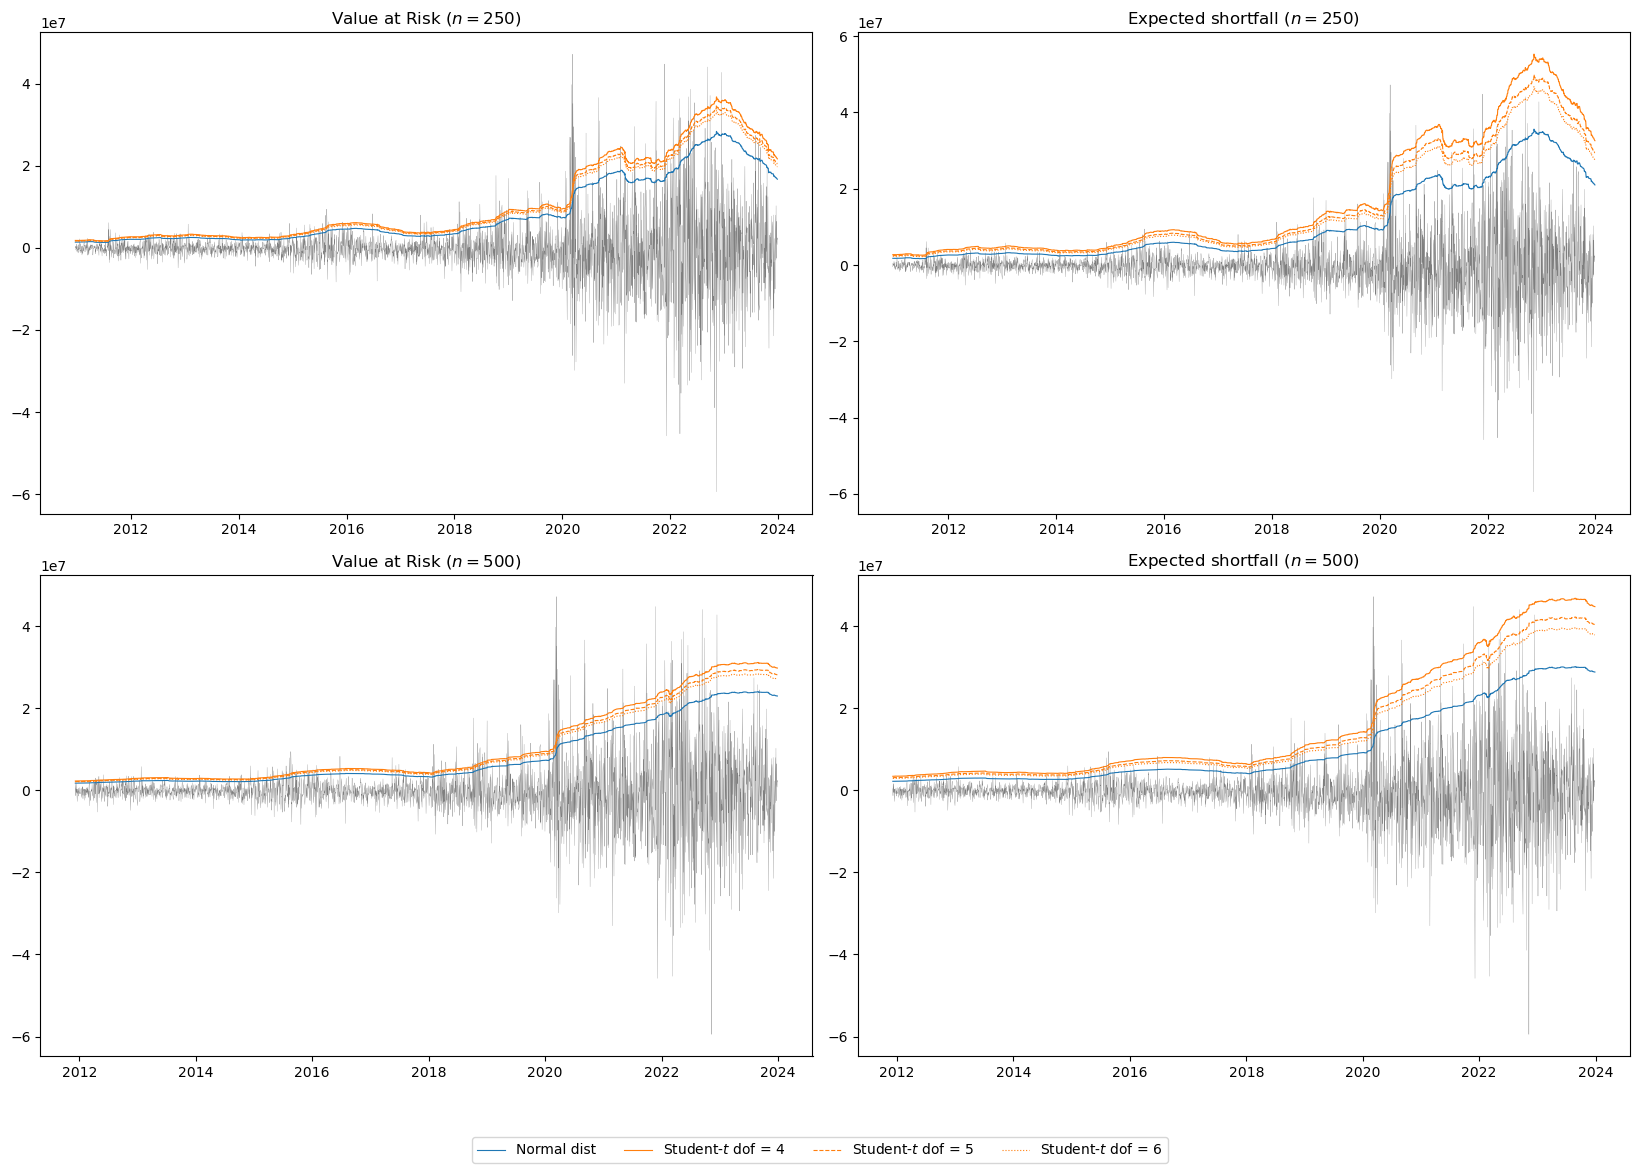

In [528]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

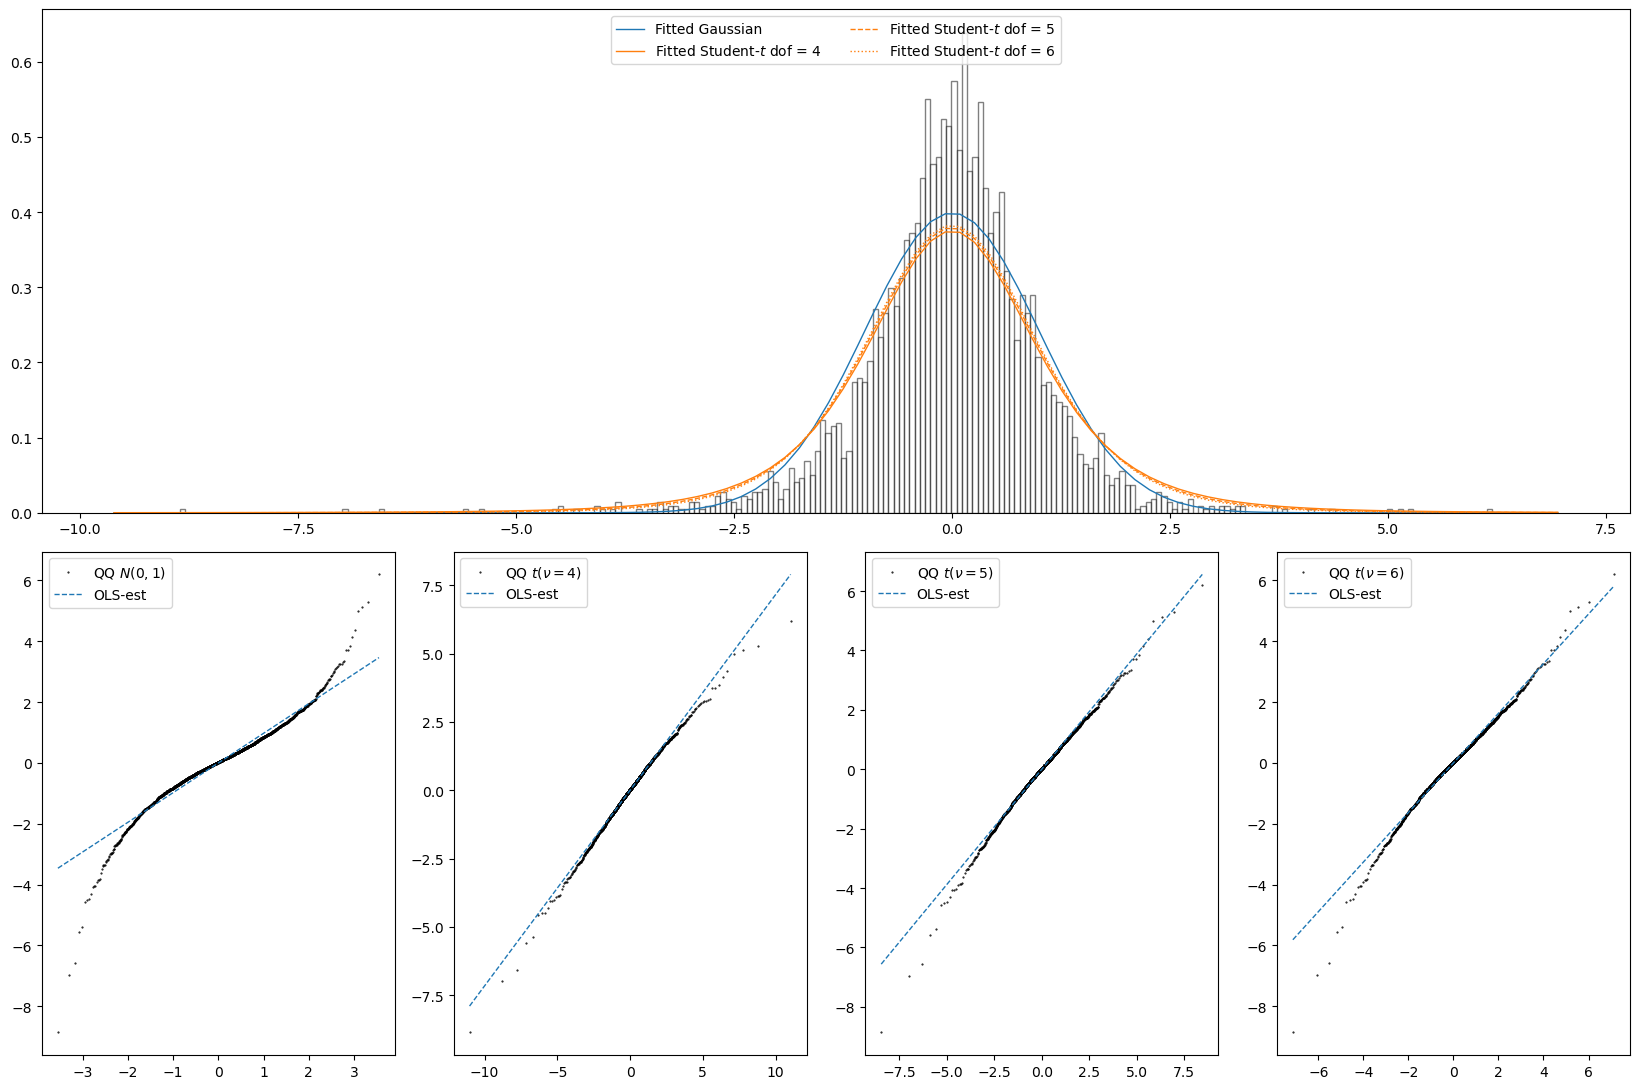

In [529]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (log_data.diff() @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [530]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [531]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df[window_size:]#.dropna()

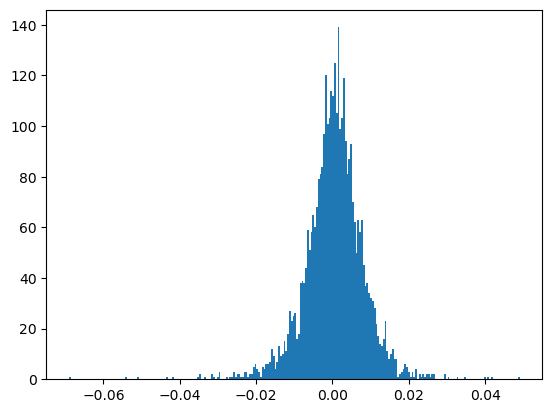

In [532]:
plt.hist(log_data.diff() @ weights, bins = 250)
plt.show()

In [533]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [534]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)

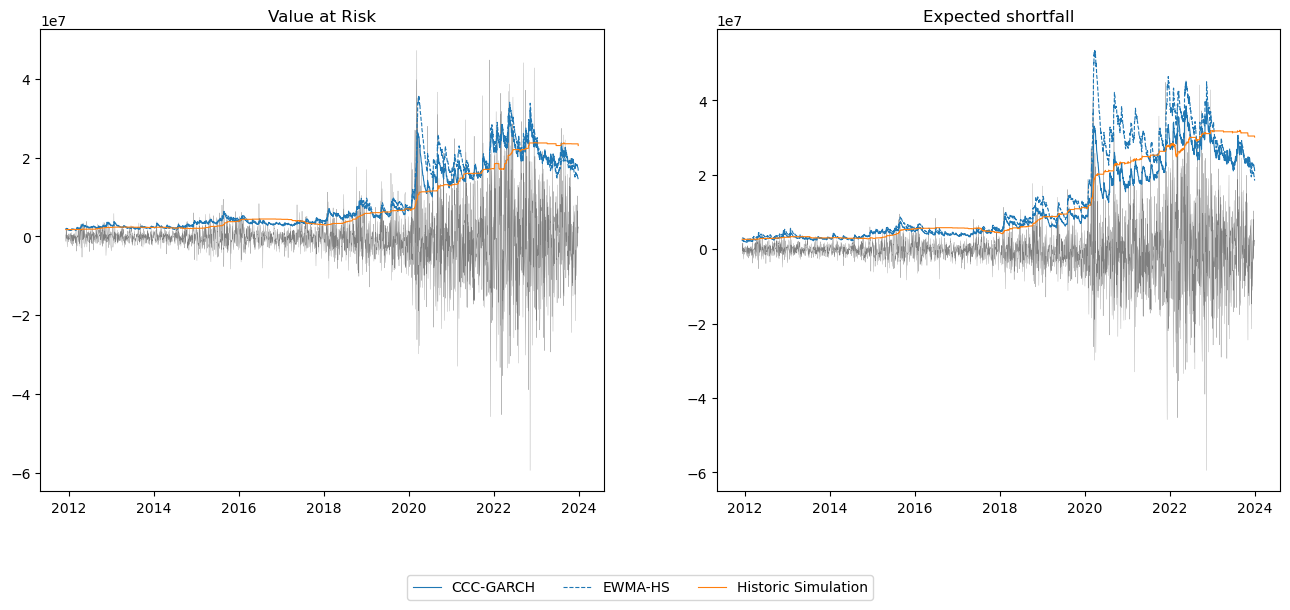

In [535]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss[window_size:].index, ES_GARCH[window_size:], label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss[window_size:].index, VaR_GARCH[window_size:], label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# BackTesting

In [536]:
# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, VaR_alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    print("\nVaR Violations: ", sum(Violations_VaR))

    n = len(Violations_VaR)     # Number of trials
    p = 1-VaR_alpha              # Expected probability of violation per trial
    x = sum(Violations_VaR)     # Observed number of violations
    alpha = 0.05                # Significance level for the test

    # Calculate P-values for two-tail test
    p_value_left = stats.binom.cdf(x, n, p)  # Probability of x or fewer successes
    p_value_right = 1 - stats.binom.cdf(x - 1, n, p)  # Probability of x or more successes
    p_value = min(p_value_left, p_value_right) * 2  # Two-tailed P-value

    if p_value <= alpha:
        print("VaR Violations amount differs significantly from Expected")

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("\nAverage ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

## Obtaining Data

In [537]:
data = log_data
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR

start_date = '2010-01-01'
end_date = '2024-01-01'
data = data[(data.index >= pd.to_datetime(start_date)) & (data.index < pd.to_datetime(end_date))]        # Keeping only the related dates
portfolio_loss, ind_loss = loss_operator(data, weights)

In [538]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = indexes_year_changes[0]                           # Days in the first period which are used to train VaR
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped

Indexes where year changes:  [259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


## VaR_95

In [539]:
alpha = .95

### Var-CoVar


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  17

Average ES Real and Theoretical:  2769453.4599569477 1987768.9405845385
ES t-Test significance of difference:  0.008944988711361117  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  16

Average ES Real and Theoretical:  2941954.042397012 2845147.735892331
ES t-Test significance of difference:  0.44153111011726653  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3327110.383197892 2924571.296916375
ES t-Test significance of difference:  0.39869619870382  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2014 

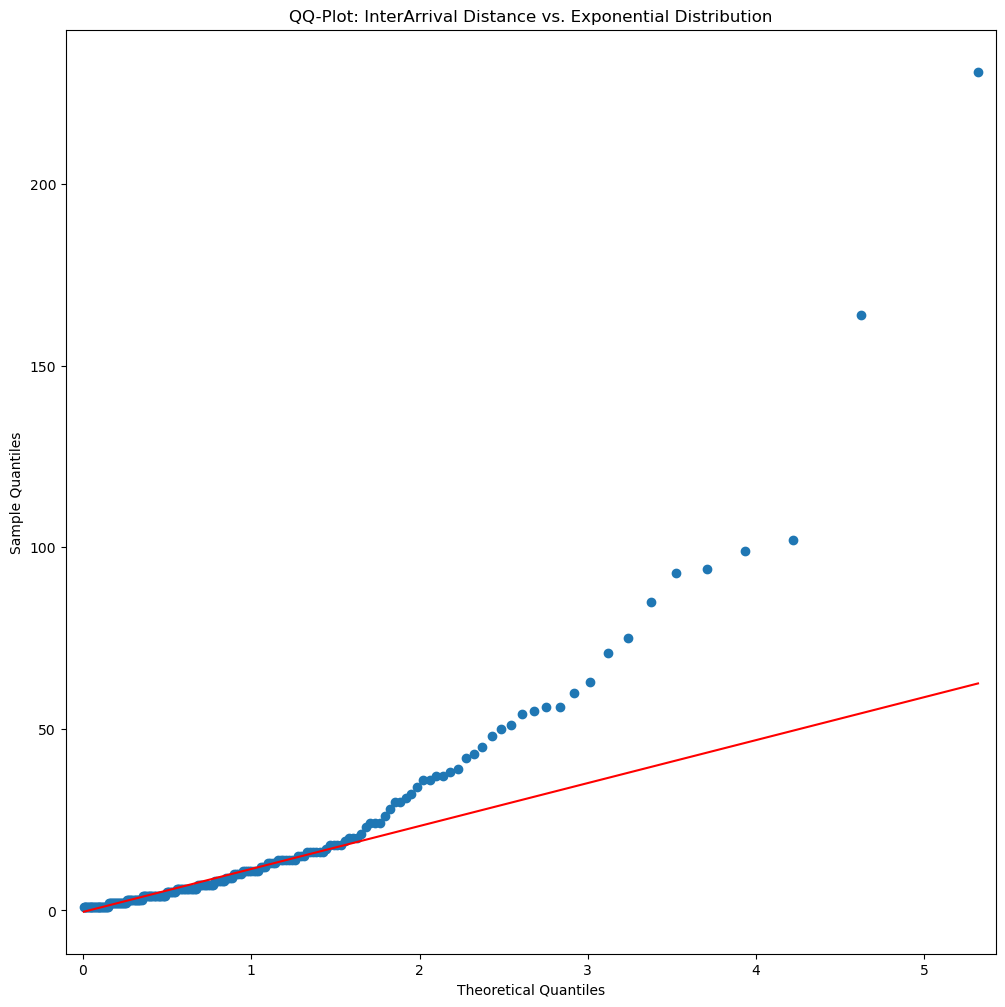


Average ES Real and Theoretical:  11563947.312688537 9533885.328313833
ES t-Test significance of difference:  0.008932451109460247  | Reject if <0.05




In [540]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  3181207.223602966 3087387.0510475426
ES t-Test significance of difference:  0.7930816461603426  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  8

Average ES Real and Theoretical:  3396409.325491178 4463738.974638244
ES t-Test significance of difference:  6.750551088864655e-41  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  3
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4138677.5666594678 4525810.609959278
ES t-Test significance of difference:  0.5688565344297694  | Reject if <0.05



Variance Covariance t-S

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


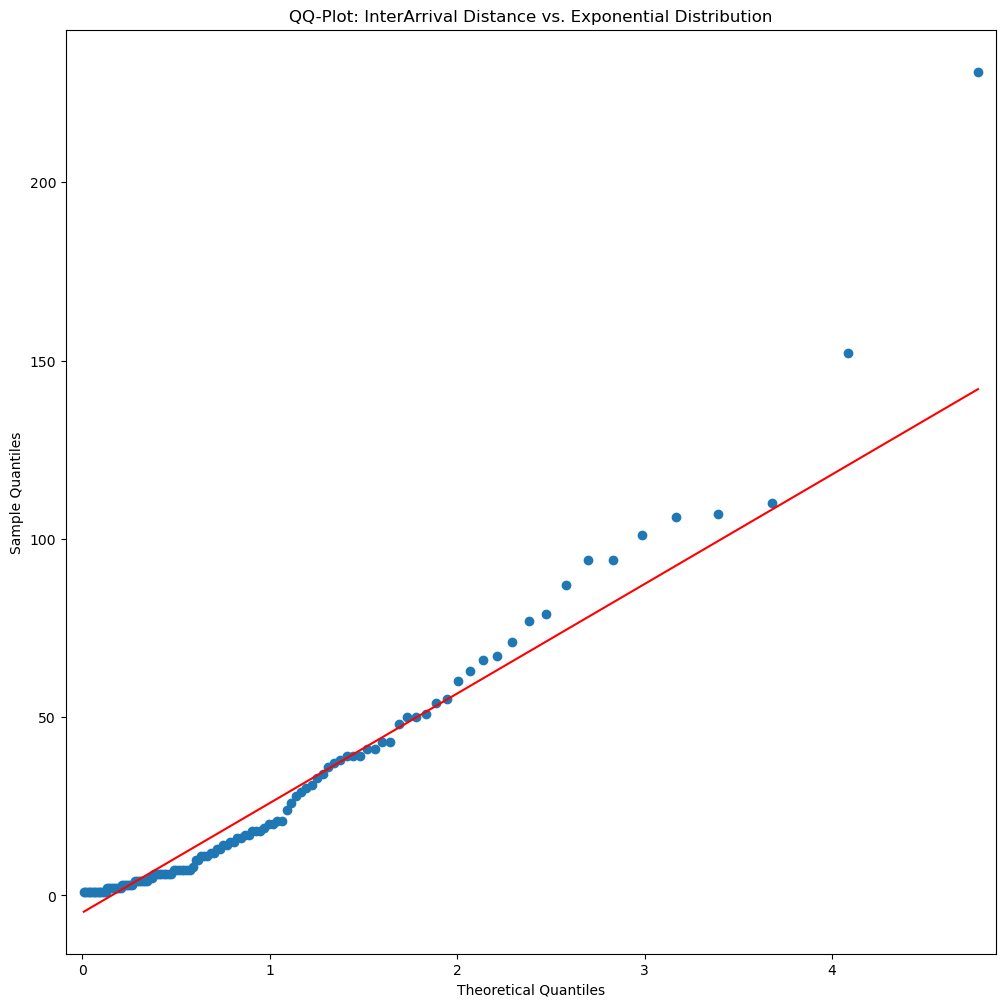


Average ES Real and Theoretical:  13186237.375765137 13932207.630446313
ES t-Test significance of difference:  0.5047154415061644  | Reject if <0.05




In [541]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  12

Average ES Real and Theoretical:  3181207.223602966 2785921.8564341934
ES t-Test significance of difference:  0.2690837250136835  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  9

Average ES Real and Theoretical:  3322756.832871833 4012057.2581624812
ES t-Test significance of difference:  3.6918390493027045e-12  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  3
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  4138677.5666594678 4083891.811390888
ES t-Test significance of difference:  0.9357384696567236  | Reject if <0.05



Variance Covariance t

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


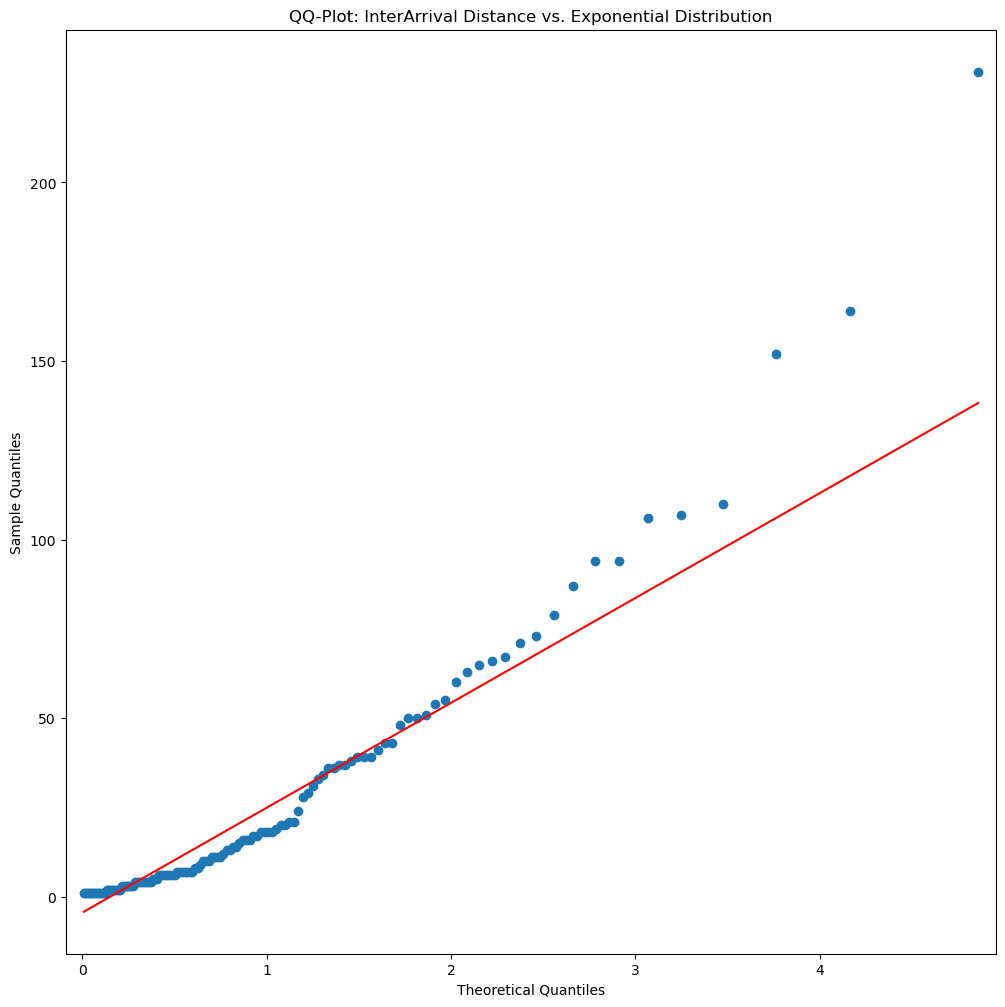


Average ES Real and Theoretical:  13185874.962750029 13038060.08994461
ES t-Test significance of difference:  0.8884261974650597  | Reject if <0.05




In [542]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  13

Average ES Real and Theoretical:  3070309.3537851367 2592820.1878480534
ES t-Test significance of difference:  0.16870983829439057  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  9

Average ES Real and Theoretical:  3322756.832871833 3763028.7498045852
ES t-Test significance of difference:  9.07281390203873e-06  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3783351.140400754 3820282.1241393774
ES t-Test significance of difference:  0.9505345920808266  | Reject if <0.05



Variance Covariance t

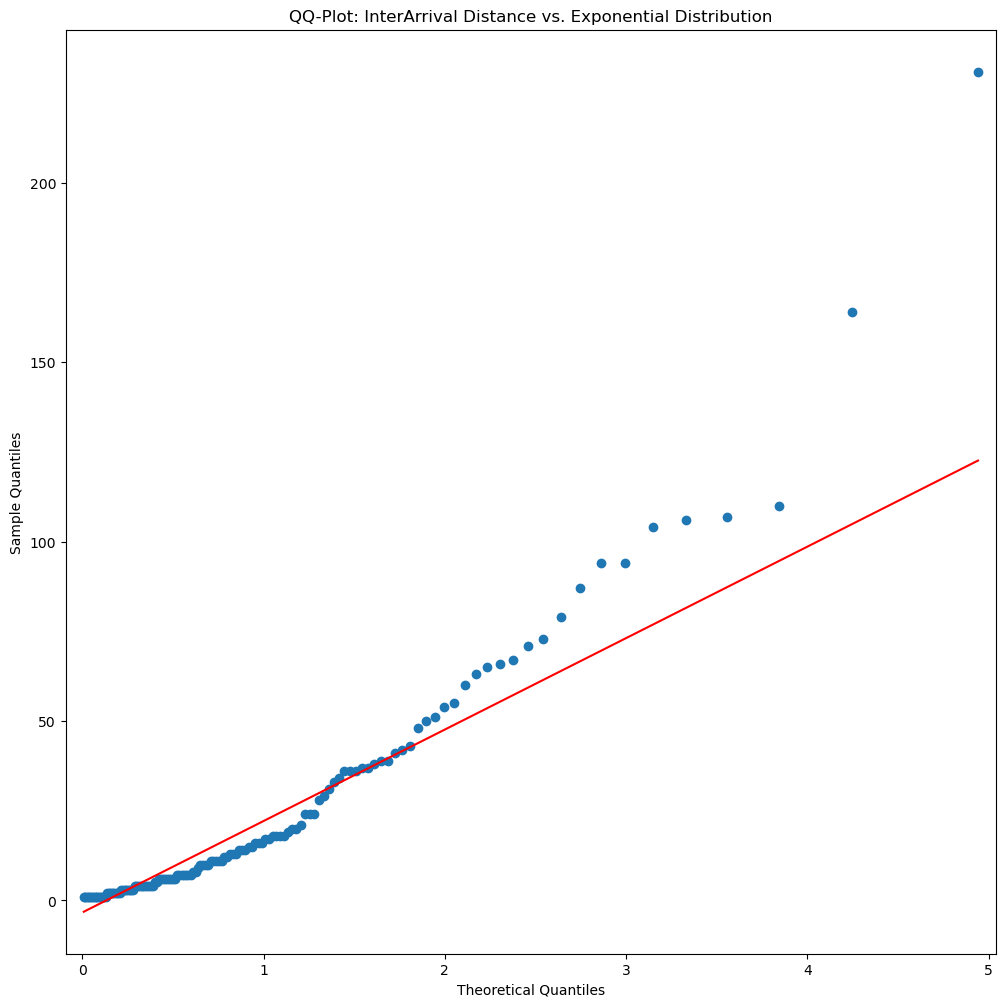


Average ES Real and Theoretical:  13175647.520103471 12678890.773172133
ES t-Test significance of difference:  0.6187282193892203  | Reject if <0.05




In [543]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  22
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2465708.187891079 2356504.7955751326
ES t-Test significance of difference:  0.6749165746559209  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  18

Average ES Real and Theoretical:  2870661.6202337258 3128620.8091084003
ES t-Test significance of difference:  0.03378357077280346  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3327110.383197892 3148690.7630287656
ES t-Test significance of difference:  0.7083525909487365  | Reject if 

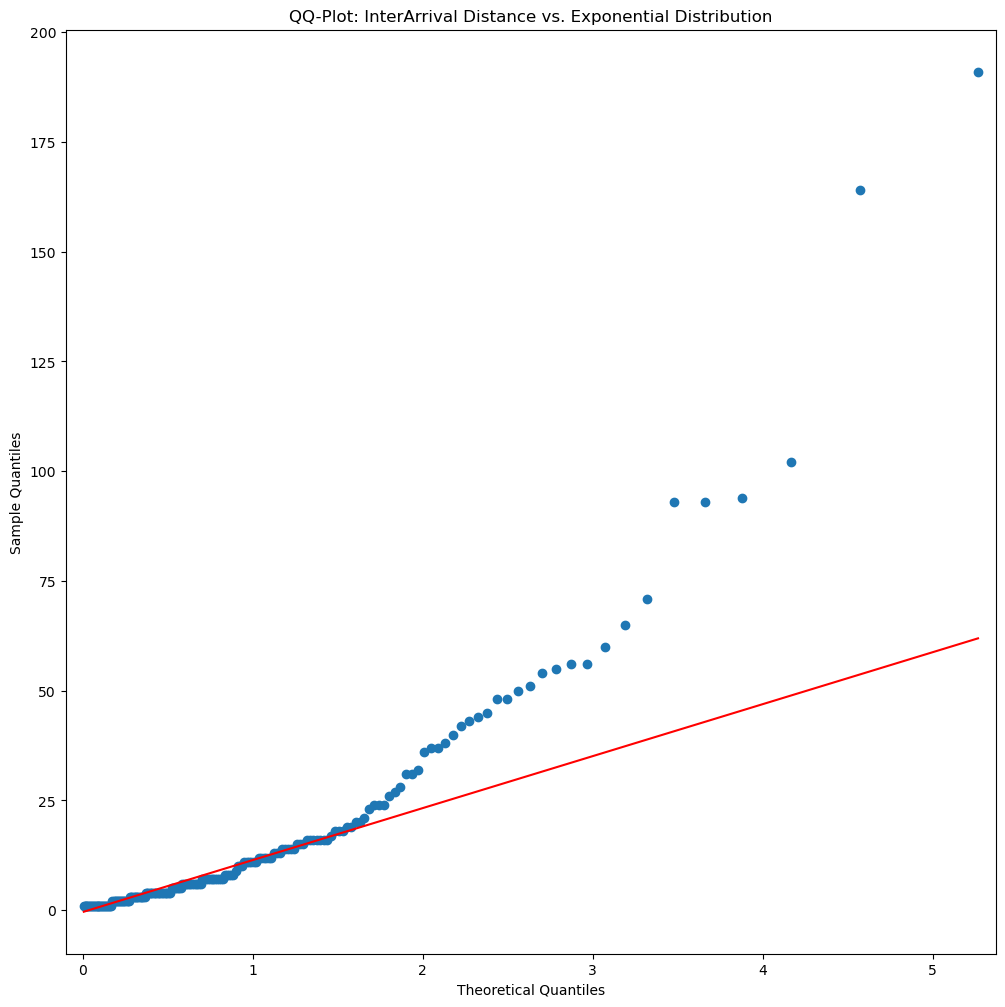


Average ES Real and Theoretical:  12161987.40748278 11704718.00738725
ES t-Test significance of difference:  0.568746013886792  | Reject if <0.05




In [544]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  13

Average ES Real and Theoretical:  3068806.4703654167 2416618.6458733464
ES t-Test significance of difference:  0.06032372519529871  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  14

Average ES Real and Theoretical:  3004917.807425746 2999055.2880129046
ES t-Test significance of difference:  0.9651874465606947  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  6
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3291001.2837359887 2792839.339020546
ES t-Test significance of difference:  0.30751451938295316  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=20

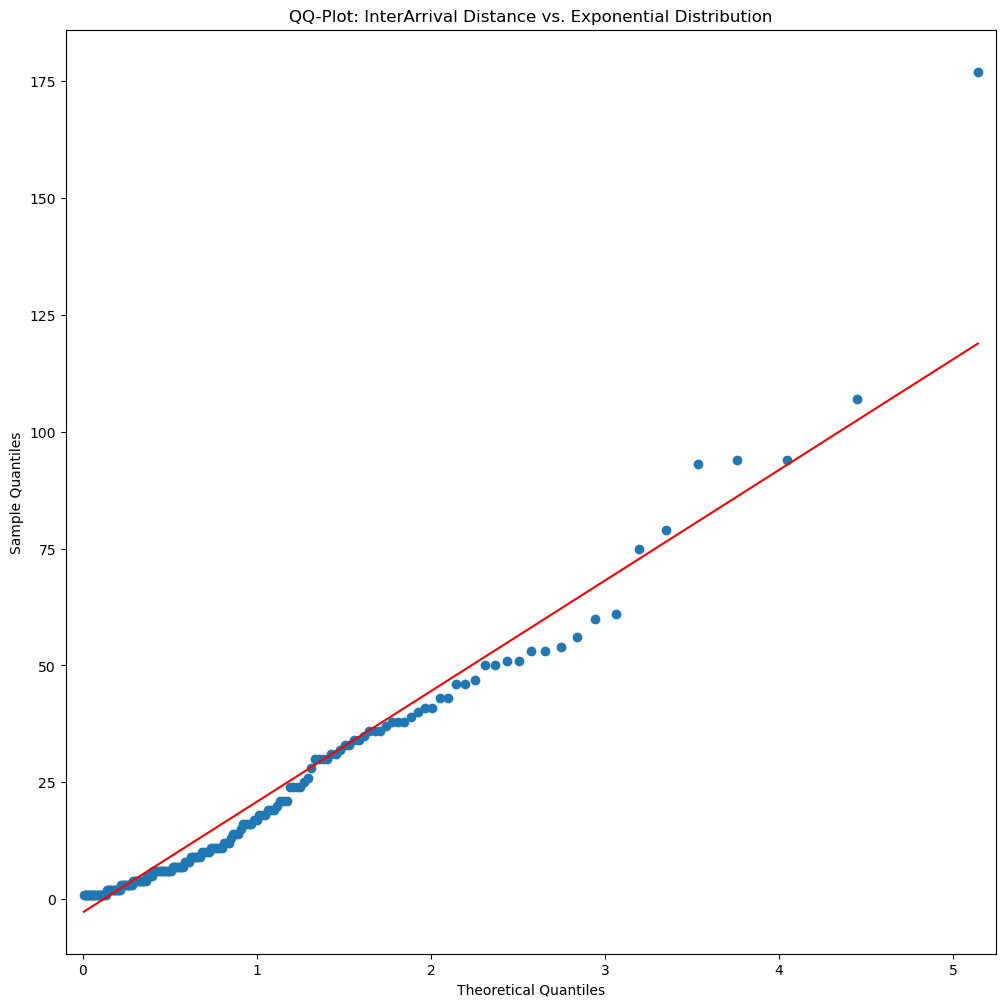


Average ES Real and Theoretical:  12635864.39432186 10835212.72702663
ES t-Test significance of difference:  0.04043375627577757  | Reject if <0.05




In [545]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.95 | period=2011 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  15

Average ES Real and Theoretical:  2794960.117421935 2571695.3913394976
ES t-Test significance of difference:  0.5172328295117774  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2012 | Trading Days=259
Expected number of VaR violations: 12.950000000000012

VaR Violations:  12

Average ES Real and Theoretical:  3092649.2926223185 3464702.918065592
ES t-Test significance of difference:  0.008368044967636358  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2013 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  7

Average ES Real and Theoretical:  3102531.6920286166 2608402.7570461286
ES t-Test significance of difference:  0.27574774006265756  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2014 | Trading Days=258
Expected number of VaR violations: 

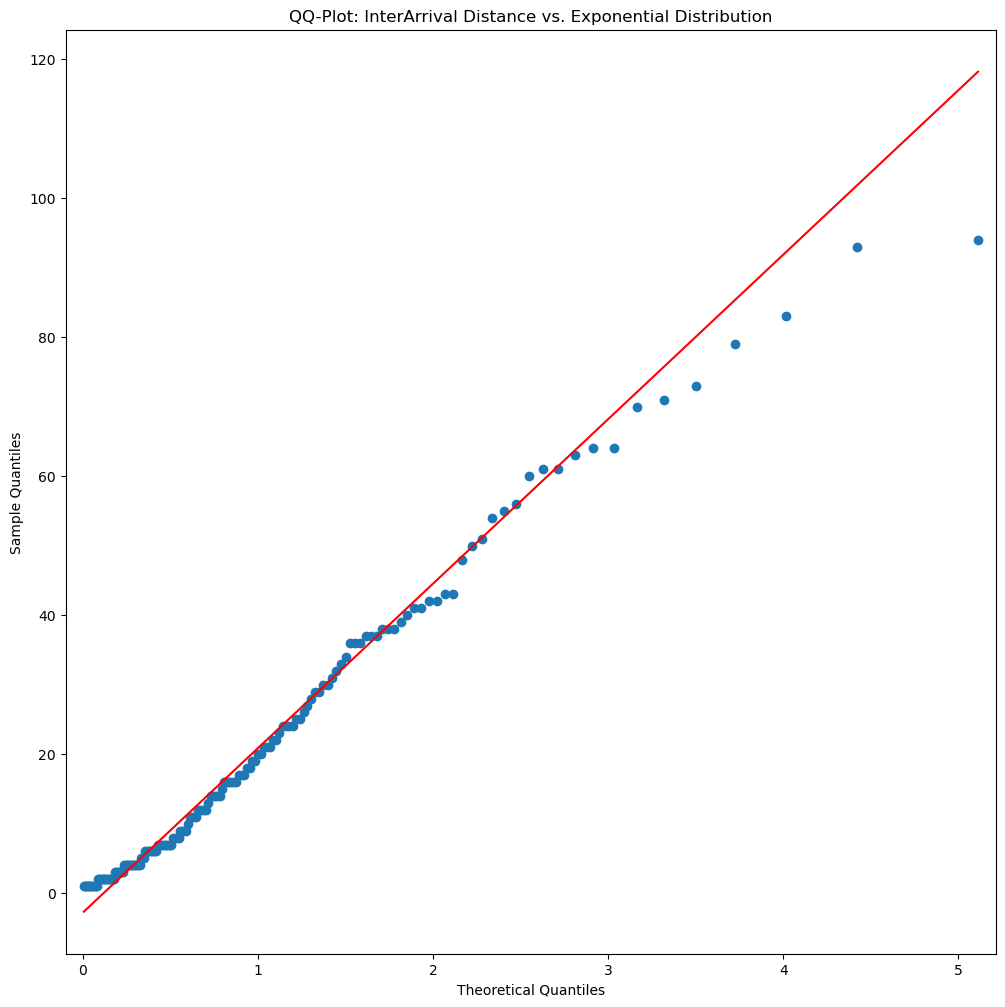


Average ES Real and Theoretical:  11595752.803713173 11811493.491587527
ES t-Test significance of difference:  0.8047870478535324  | Reject if <0.05




In [546]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

## VaR_99

In [547]:
alpha = .99

### Var-CoVaR


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3497132.970013745 2519145.5168764424
ES t-Test significance of difference:  0.020720911341988467  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  6

Average ES Real and Theoretical:  3500204.6853484553 3757466.6084506256
ES t-Test significance of difference:  2.9594920424482167e-05  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  4138677.5666594678 3766076.4367211196
ES t-Test significance of difference:  0.5834515978607043  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


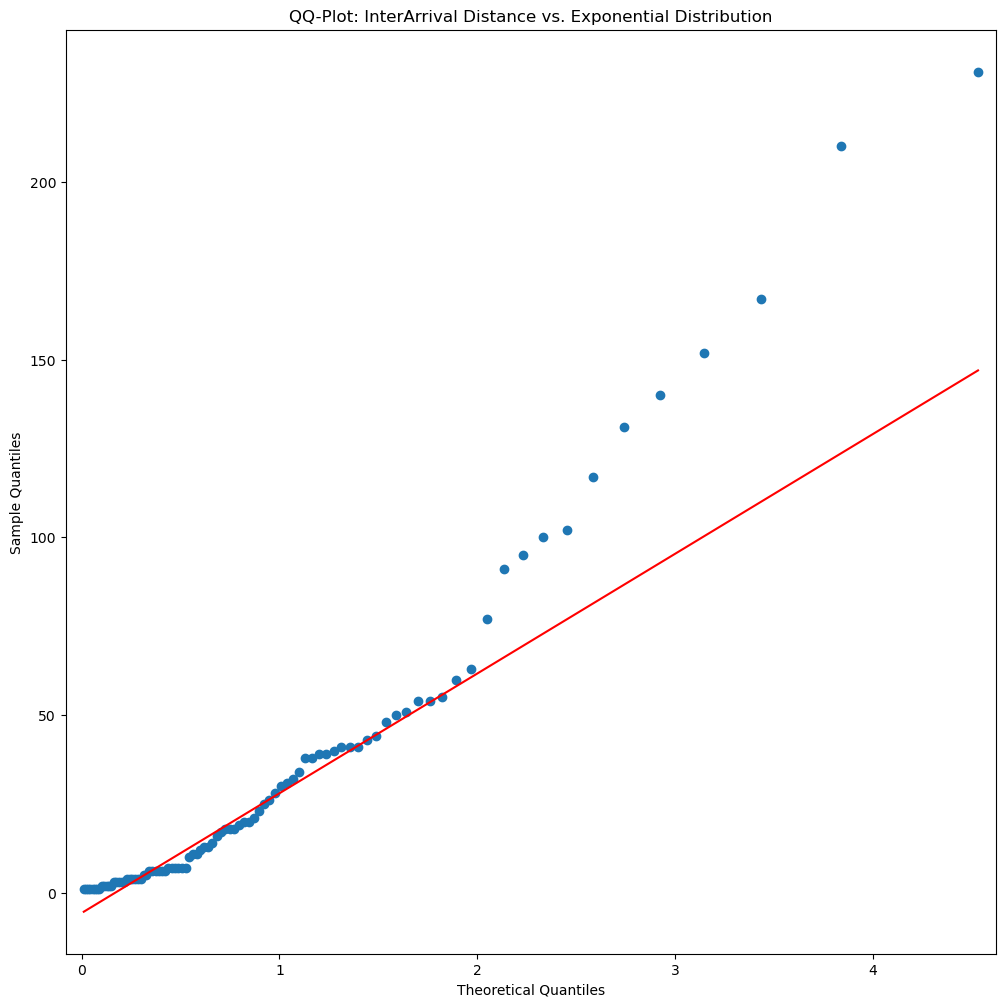


Average ES Real and Theoretical:  14761789.762928125 12308420.680389812
ES t-Test significance of difference:  0.06516065620664296  | Reject if <0.05




In [548]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  5044177.7119212635 4705884.383292824
ES t-Test significance of difference:  0.45306511493263846  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799520.8378969375 7802439.94491729
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Viola

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


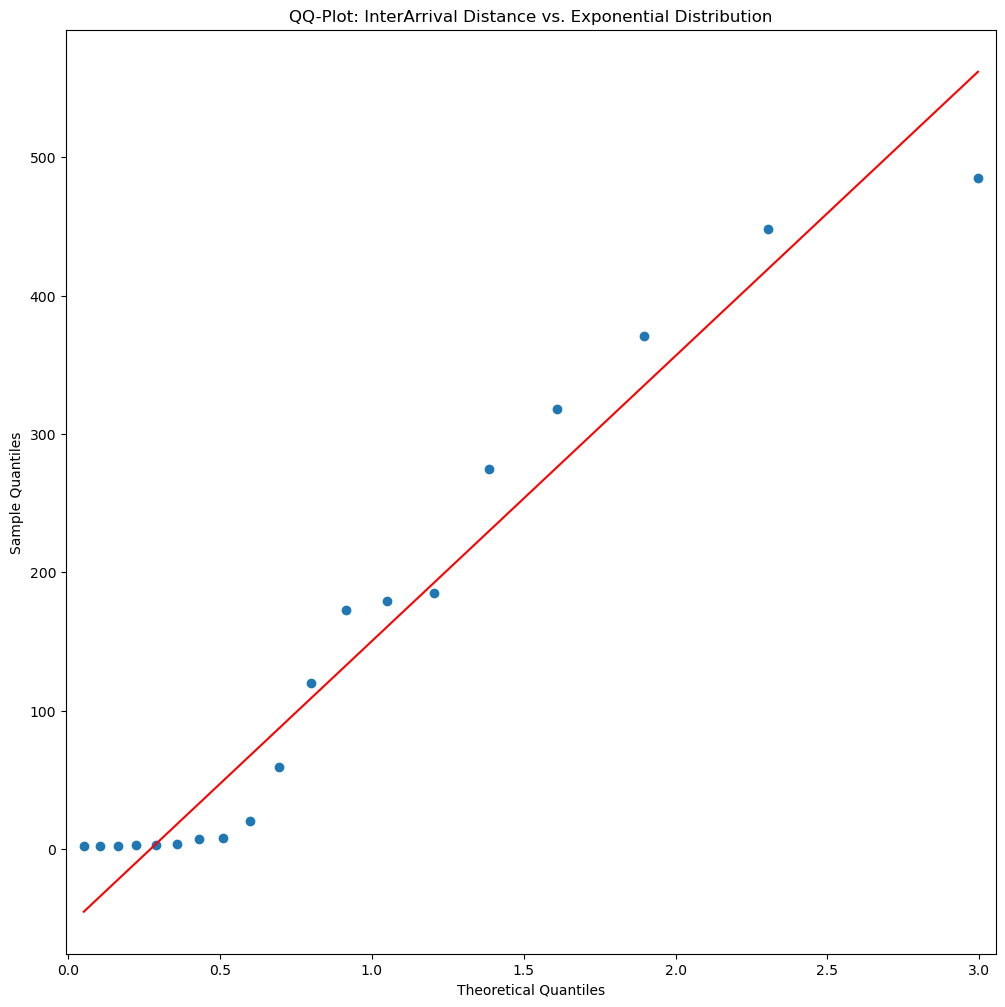


Average ES Real and Theoretical:  20240925.601831775 21731086.87092299
ES t-Test significance of difference:  0.6370092252782128  | Reject if <0.05




In [549]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  4703616.901263823 4210331.205546489
ES t-Test significance of difference:  0.2716093800301629  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799520.8378969375 6654391.4358573975
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Viola

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


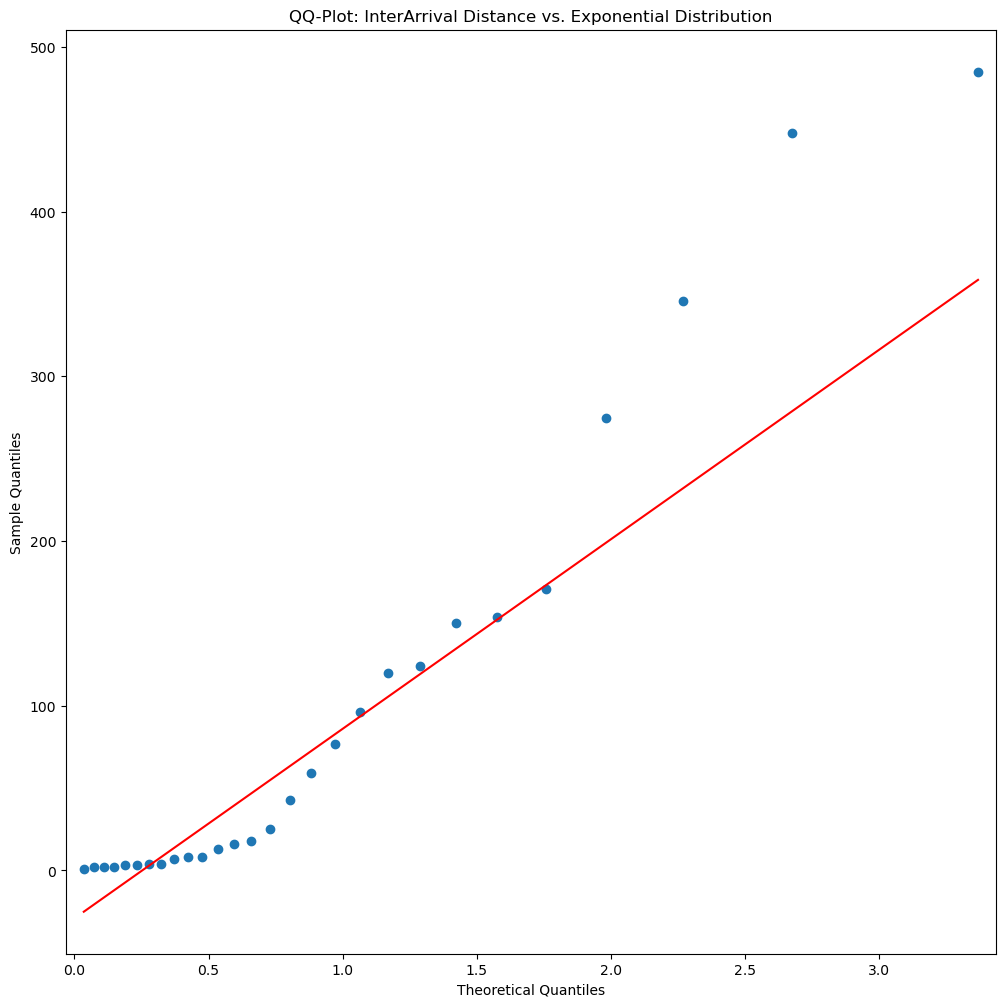


Average ES Real and Theoretical:  18076615.80963807 17870700.44349936
ES t-Test significance of difference:  0.933031936727472  | Reject if <0.05




In [550]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  4703616.901263823 3813261.637609641
ES t-Test significance of difference:  0.047222946142066874  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799520.8378969375 6026826.4763982035
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Vio

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


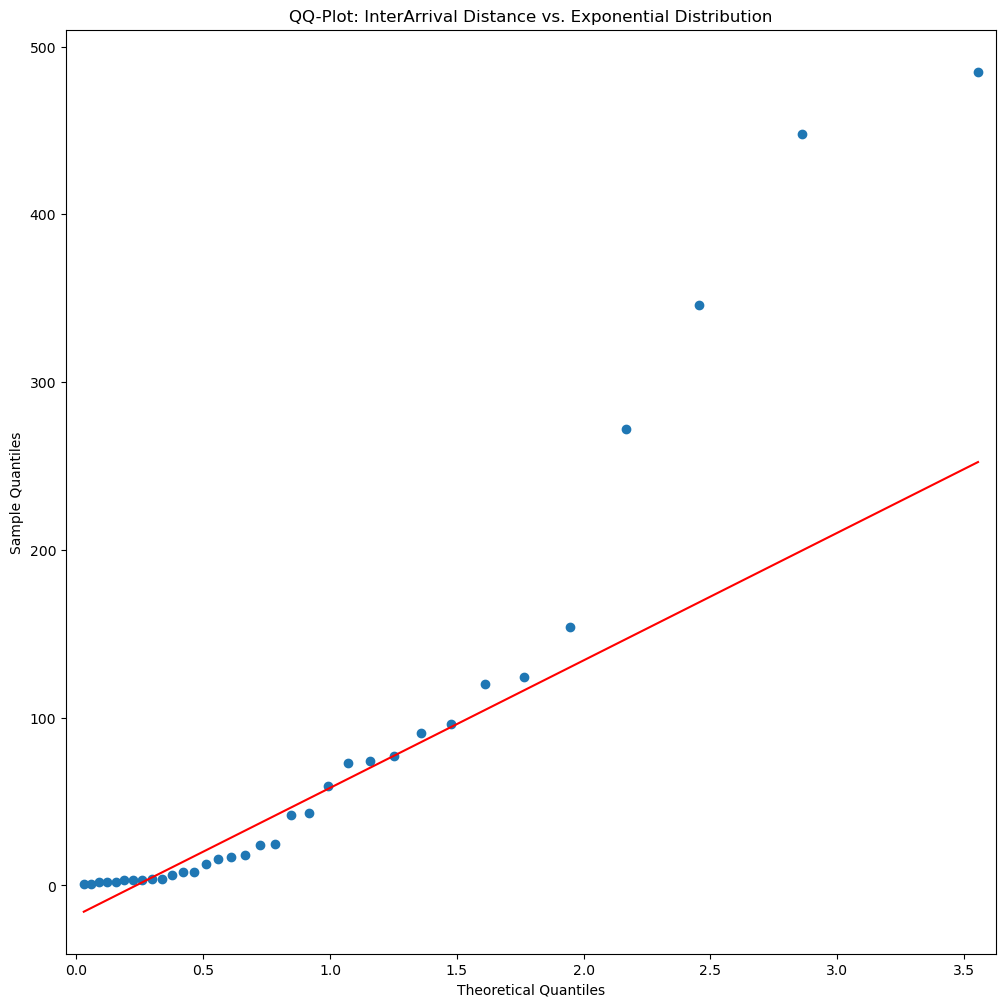


Average ES Real and Theoretical:  17448268.944305517 16531960.56673019
ES t-Test significance of difference:  0.6674316510231054  | Reject if <0.05




In [551]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5

Average ES Real and Theoretical:  4055351.662876551 3821352.2359499536
ES t-Test significance of difference:  0.7006841719936202  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  2

Average ES Real and Theoretical:  3504675.2040472096 3640941.4472756702
ES t-Test significance of difference:  2.9177738904617853e-05  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  1

Average ES Real and Theoretical:  5799520.8378969375 3681268.061119648
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.58000000000000

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


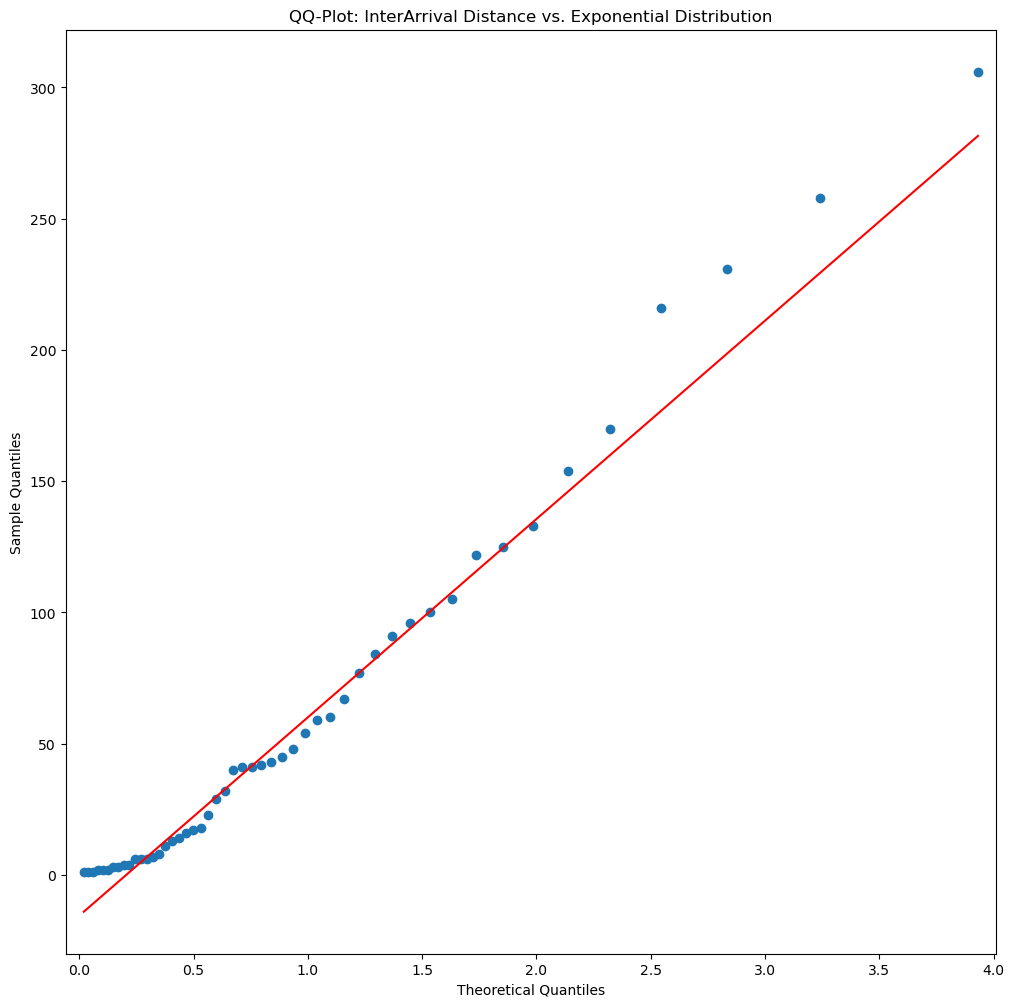


Average ES Real and Theoretical:  16641064.324499635 16015099.943068229
ES t-Test significance of difference:  0.7511254216384113  | Reject if <0.05




In [552]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  7
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  3791171.7027785145 3151701.01925387
ES t-Test significance of difference:  0.18761278860713815  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  3

Average ES Real and Theoretical:  3327267.444931872 3457434.030766614
ES t-Test significance of difference:  0.5171703066152047  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  4138677.5666594678 3721831.780238597
ES t-Test significance of difference:  0.5395695624724145  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | T

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


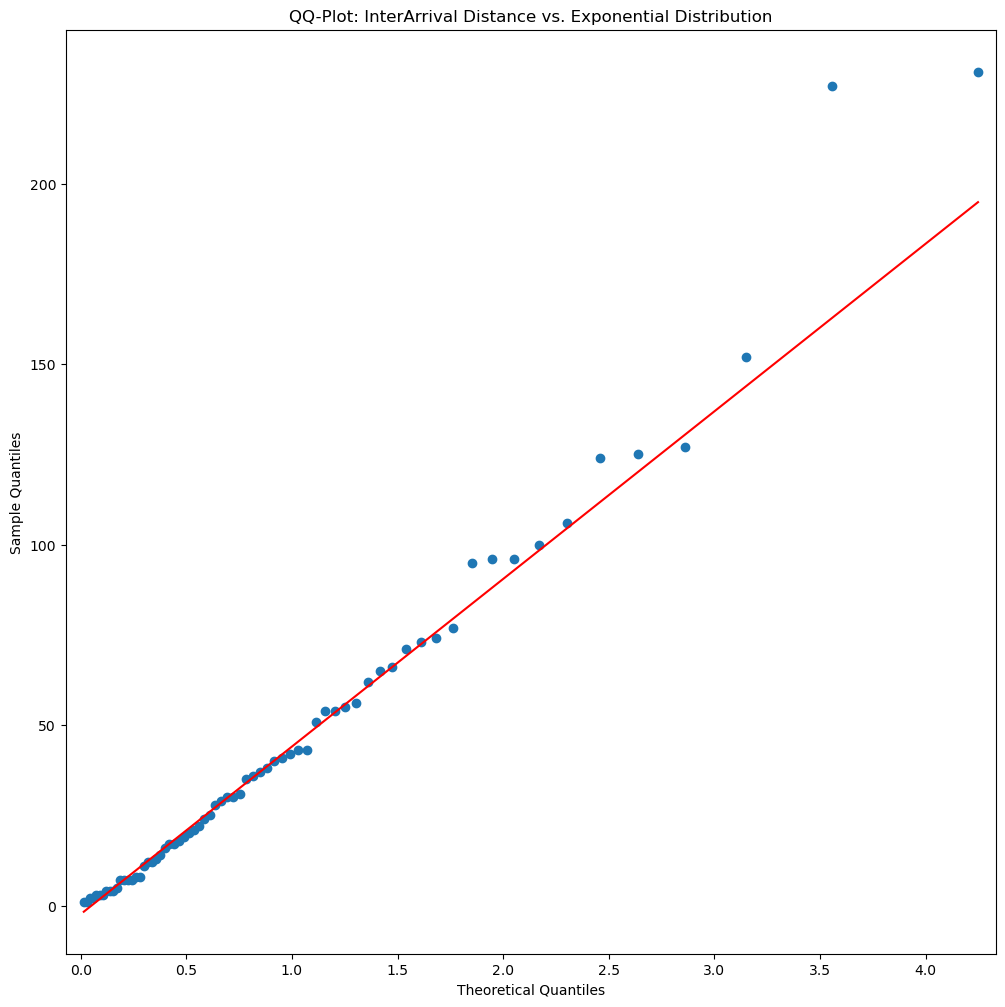


Average ES Real and Theoretical:  15552747.731984574 13134409.005962757
ES t-Test significance of difference:  0.11182596837461474  | Reject if <0.05




In [553]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.99 | period=2011 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  3

Average ES Real and Theoretical:  5044177.7119212635 4392650.942782613
ES t-Test significance of difference:  0.14844432306784947  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2012 | Trading Days=259
Expected number of VaR violations: 2.5900000000000025

VaR Violations:  2

Average ES Real and Theoretical:  3309516.8172327555 3584281.6942973416
ES t-Test significance of difference:  0.00913496829489535  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  4

Average ES Real and Theoretical:  3783351.140400754 3559168.8117134506
ES t-Test significance of difference:  0.7064900923996402  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=258
Expected number of VaR violations: 2.5

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


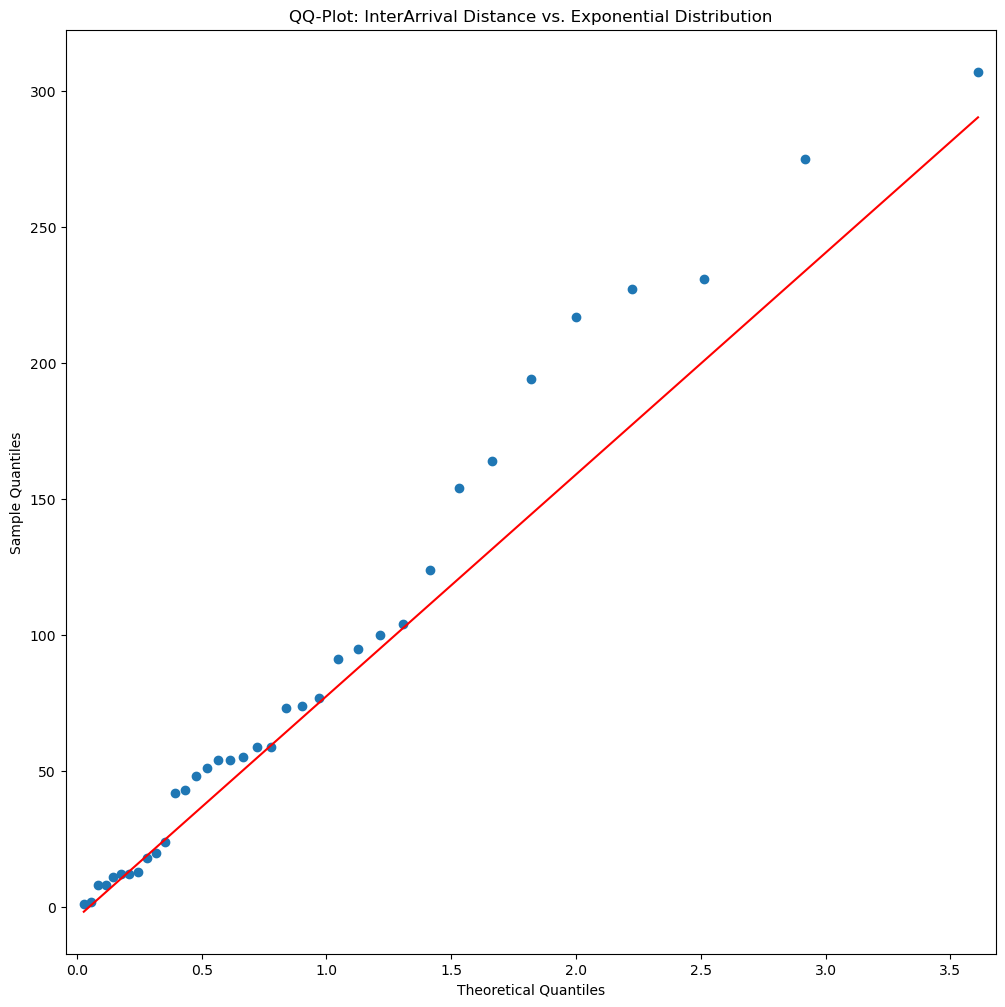


Average ES Real and Theoretical:  15362251.003018644 15121320.864167942
ES t-Test significance of difference:  0.9091128176012981  | Reject if <0.05




In [554]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

# Stress Testing

## Shocking APPL by 20-40%

It is exactly same portfolio otherwise, thus we can compare with the previously obtained VaR/ES

In [555]:
# Getting raw data to introduce a shock

# Stock and FX Data
start_date = '2010-01-01'
end_date = '2024-01-01'
stocks = ['AAPL', 'ASML.AS', 'AIR.PA', 'MC.PA', 'SC0D.DE', 'EURUSD=X']
stock_data = yf.download(' '.join(stocks), start=start_date, end=end_date)
# Combine data
data = pd.DataFrame(stock_data['Adj Close'].values, columns = stock_data['Adj Close'].columns, index = stock_data.index)

# Interest Rate Data
euribor_3M = pd.read_csv("BundesBank Euribor 3M Daily.csv")
euribor_3M["Date"] = pd.to_datetime(euribor_3M["Date"], format='%Y-%m-%d')
euribor_3M = euribor_3M[(euribor_3M["Date"] >= pd.to_datetime(start_date)) & (euribor_3M["Date"] <= pd.to_datetime(end_date))]        # Keeping only the related dates
euribor_3M = euribor_3M.set_index('Date')
data = pd.merge(data, euribor_3M, on='Date', how='inner')

# Make names more readable
data = data.rename(columns={'ASML.AS': 'ASML', 'AIR.PA': 'AIRBUS', 'MC.PA': 'LVMH', 'SC0D.DE': 'EURO50', 'EURIBOR_3M': 'EURIBOR', 'EURUSD=X':'EUR_USD'})
# Delete Days for which no trading happened (some holiday probably, we didn't go to work)
data = data.loc[~(data[['AAPL', 'AIRBUS', 'ASML', 'LVMH', 'EURO50']].isnull()).all(axis=1)]
# Impute missing quotes with closest valid ones
data = data.ffill().bfill()

[*********************100%%**********************]  6 of 6 completed


In [556]:
# Shocking Parameters

# Shocking AAPL on the last week of 2021
start_date = '2021-12-23'
end_date = '2022-01-01'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

# Shocking AAPL on the last week of 2021
start_date = '2021-12-25'
end_date = '2021-12-27'
data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] = data.loc[(data.index >= pd.to_datetime(start_date)) & (data.index <= pd.to_datetime(end_date)), "AAPL"] * 0.8        # Keeping only the related dates

In [557]:
# Obtaining Loss Operator

credit = ((1 + data['EURIBOR'] / 100) ** (1 / 365)) - 1
data['EURIBOR'] = credit
credit_loss, credit_val = credit_risk(data['EURIBOR'])

# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .1, .1, .0, .1 , .1, .4]     # AAPL$, AIRBUS€, ASML€, EUR_USD, LVMH€, EURO50€, EURIBOR
data['AAPL'] = data['AAPL'] / data['EUR_USD']

log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])
portfolio_loss, ind_loss = loss_operator(data, weights)

In [558]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = indexes_year_changes[0]                           # Days in the first period which are used to train VaR
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped

Indexes where year changes:  [259, 517, 776, 1034, 1292, 1550, 1808, 2066, 2324, 2583, 2842, 3101, 3359, 3616]


## .95

In [559]:
alpha = .95

In [560]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  11

Average ES Real and Theoretical:  36069688.94491722 37680544.98925947
ES t-Test significance of difference:  0.21856197667503652  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  4
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  25301444.225352183 27066897.946576033
ES t-Test significance of difference:  0.01722995776131052  | Reject if <0.05




In [561]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  40224989.665192634 58774588.41540183
ES t-Test significance of difference:  1.2599128580552504e-11  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  0
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [562]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  39750007.74825299 54063352.9838535
ES t-Test significance of difference:  2.3416324192030693e-24  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  1
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  27452323.46148307 37919347.36443292
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


In [563]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  39750007.74825299 50707639.12333856
ES t-Test significance of difference:  6.376618871282418e-15  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  2
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  26611519.173867088 35597404.77676555
ES t-Test significance of difference:  1.3083680394142299e-51  | Reject if <0.05




In [564]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  20

Average ES Real and Theoretical:  31059424.847429473 42648248.67165016
ES t-Test significance of difference:  1.1626241689109507e-14  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  24211406.377256785 27482701.7568842
ES t-Test significance of difference:  0.004147639342877547  | Reject if <0.05




In [565]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  18

Average ES Real and Theoretical:  32016877.935069032 30672304.730861887
ES t-Test significance of difference:  0.3535168430665381  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  5
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  24554363.681809716 27838612.32865419
ES t-Test significance of difference:  0.00023675706924794102  | Reject if <0.05




In [566]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.95 | period=2022 | Trading Days=258
Expected number of VaR violations: 12.900000000000011

VaR Violations:  9

Average ES Real and Theoretical:  35649869.66435775 42919613.820960976
ES t-Test significance of difference:  0.00014497486242276856  | Reject if <0.05



Variance Covariance Normal | VaR0.95 | period=2023 | Trading Days=257
Expected number of VaR violations: 12.850000000000012

VaR Violations:  10

Average ES Real and Theoretical:  21198364.28551646 23349840.241237164
ES t-Test significance of difference:  0.08296780891707625  | Reject if <0.05




## .99

In [567]:
alpha = .99

In [568]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [569]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [570]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [571]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [572]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [573]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  5

Average ES Real and Theoretical:  37715548.62486837 35177905.16775527
ES t-Test significance of difference:  0.2925357695822106  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05




c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [574]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(11, 13):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2011+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)


Variance Covariance Normal | VaR0.99 | period=2022 | Trading Days=258
Expected number of VaR violations: 2.5800000000000023

VaR Violations:  2

Average ES Real and Theoretical:  43443737.169923544 69430193.84058605
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2023 | Trading Days=257
Expected number of VaR violations: 2.570000000000002

VaR Violations:  1

Average ES Real and Theoretical:  27452323.46148307 33012741.78735737
ES t-Test significance of difference:  0.0  | Reject if <0.05




C:\Users\PAOvi\AppData\Local\Temp\ipykernel_21820\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
